# Coupled-resonator frequency comb — NumPy/SciPy port of `Comb_Code.nb`

Two coupled modes, x1 driven near 11.35 MHz, x2 near 2×ω1 (2:1 internal resonance):

$$\ddot x_1 + \eta_1\dot x_1 + \omega_1^2 x_1 + \lambda_1 x_1 x_2 = F\cos(\Omega_d t + \tau)$$
$$\ddot x_2 + \eta_2\dot x_2 + \omega_2^2 x_2 + \alpha_2 x_1^2 + \beta_2 x_2^3 = 0$$

| Mathematica | Python |
|---|---|
| `NDSolveValue[..., MaxSteps->Infinity]` | `scipy.integrate.solve_ivp(method="DOP853")` on the first-order system |
| `sol[[i]] /@ timePoints` | `t_eval=` grid passed to the solver |
| `Fourier[x]` (default `FourierParameters->{0,1}`) | `np.fft.fft(x) / sqrt(n)` (same magnitude) |
| `Position[freqs, _?(10e6<=#<=40e6&)]` | boolean mask |
| `Plot` / `ListLinePlot` | `matplotlib` |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import time

## 1. Parameters
The original cell sets some parameters twice. Only the **final** values affect the result, and those are used below (the earlier, overridden values are kept as comments).

In [2]:
w1 = 2*np.pi*10.7e6            # ω1  [rad/s]
w2 = 2*np.pi*22.94e6           # ω2  [rad/s]
rfeq = w2 / w1

# Fixed drive frequency
fd = 11.35e6
Wd = 2*np.pi*fd                # Ωd

Q1, Q2 = 886, 600
eta1 = w1 / Q1                 # η1
eta2 = w2 / Q2                 # η2

# Overridden in the original:  α1 = 0.9e13, α2 = 0.9e15
lam1  = 1.6e15                 # λ1
lam2  = 0 * 0.9e15             # λ2  (term commented out in the EOM anyway)
alpha1 = 0 * 0.9e15            # α1  (term commented out in the EOM anyway)
alpha2 = 0.9e15                # α2
beta1 = 0 * 2e14               # β1  (term commented out in the EOM anyway)
beta2 = rfeq * 9e14            # β2

tau = 0.0                      # drive phase
tf  = 0.0008                   # total integration time [s]
F   = 1e15                     # driving force

## 2. Equations of motion
State vector `y = [x1, x1', x2, x2']`. The terms that are commented out in the Mathematica EOM (`α1 x1²`, `β1 x1³`, `λ2 x1 x2`) are left out here too.

In [3]:
def rhs(t, y):
    x1, v1, x2, v2 = y
    a1 = F*np.cos(Wd*t + tau) - eta1*v1 - w1**2*x1 - lam1*x1*x2
    a2 = -eta2*v2 - w2**2*x2 - alpha2*x1**2 - beta2*x2**3
    return [v1, a1, v2, a2]

## 3–4. Initial conditions & solve
The solver returns values at the sampling grid from §6 (`fs`, from 0 to `tf`). The time-domain plot uses the full grid, and the FFT uses its second half, so one solve covers both.

Tolerances are tighter than NDSolve's defaults. At `rtol=1e-10` vs `1e-12` the trajectories agree to ~2e-6, so the solution has converged. Expect roughly 1 minute of runtime.

In [4]:
y0 = [0.0, 0.0, 0.0, 0.0]       # x1(0)=x1'(0)=x2(0)=x2'(0)=0

# Sampling grid (section 6), defined here so the solver outputs directly on it
fs = 4*2*22.9e6
dt = 1/fs
N_all = int(np.floor(tf/dt + 1e-9)) + 1
t_all = dt*np.arange(N_all)

t0 = time.time()
sol = solve_ivp(rhs, (0, tf), y0, method="DOP853", t_eval=t_all,
                rtol=1e-10, atol=1e-14,
                first_step=1e-11)   # small first step avoids a bad initial trial step
print(sol.message, f"| {time.time()-t0:.1f} s | {sol.nfev:,} RHS evals")
x1_all, x2_all = sol.y[0], sol.y[2]

The solver successfully reached the end of the integration interval. | 55.8 s | 6,228,232 RHS evals


## 5. Time-domain plot

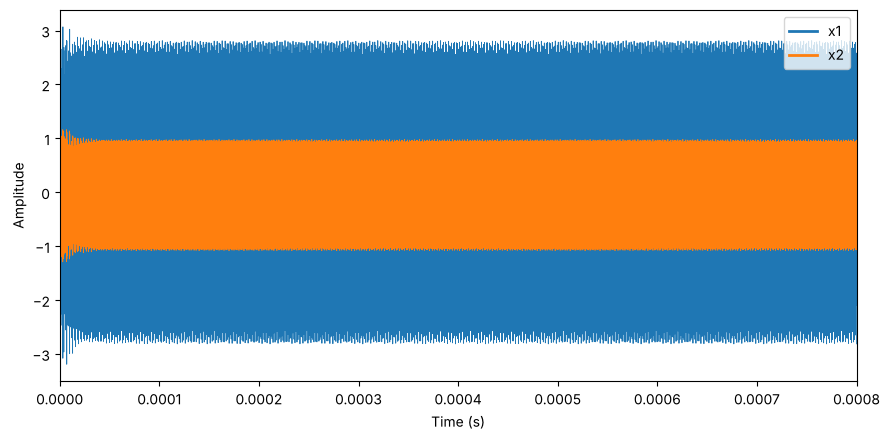

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(t_all, x1_all, lw=0.6, label="x1")
ax.plot(t_all, x2_all, lw=0.6, label="x2")
ax.set_xlabel("Time (s)"); ax.set_ylabel("Amplitude")
ax.set_xlim(0, tf)
leg = ax.legend(loc="upper right")
for h in leg.get_lines(): h.set_linewidth(2)
plt.tight_layout(); plt.show()

## 6–7. Sample x1 and x2 over the second half
`Range[tStart, tf, dt]` includes both endpoints, which gives n = 73281 samples, matching the original.

In [6]:
tStart = tf/2
mask = t_all >= tStart - 1e-15
timePoints = t_all[mask]

signal1 = x1_all[mask].copy()
signal2 = x2_all[mask].copy()
print(len(timePoints), timePoints[0], timePoints[-1])

73281 0.0004 0.0008


## 8–9. Remove DC and sum

In [7]:
signal1 -= signal1.mean()
signal2 -= signal2.mean()
signalSum = signal1 + signal2

## 10. FFT
Mathematica's `Fourier` scales by 1/√n, so `Abs[fft]/n` corresponds to `|np.fft.fft| / n**1.5`. The spectrum is normalized later anyway, so the scaling only matters if you use `mag` directly.

In [8]:
n = len(signalSum)
fft = np.fft.fft(signalSum) / np.sqrt(n)   # Mathematica normalization
freqs = np.arange(n) * (fs/n)
mag = np.abs(fft) / n

half = n // 2
freqs = freqs[:half]
mag = mag[:half]

## 11–12. Select 10–40 MHz and normalize

In [9]:
sel = (freqs >= 10e6) & (freqs <= 40e6)
freqPlot = freqs[sel] / 1e6     # MHz
magPlot = mag[sel]
magNorm = magPlot / magPlot.max()

## 13. Linear FFT plot

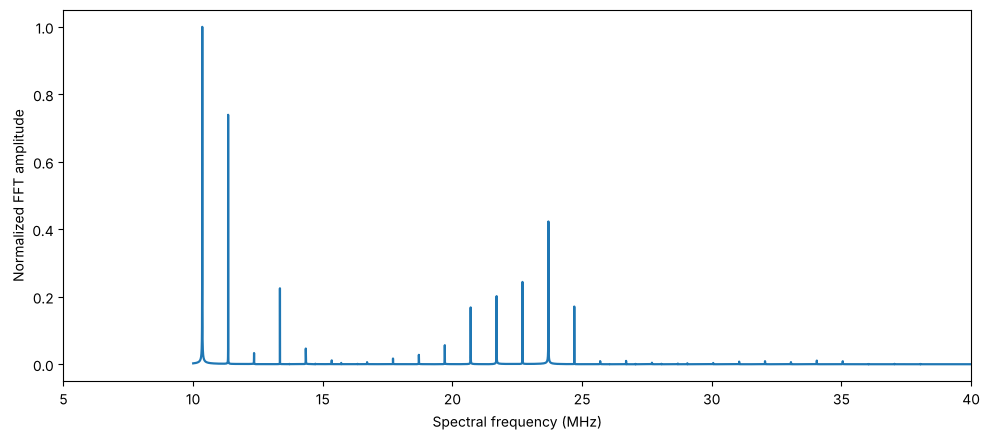

In [10]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(freqPlot, magNorm, lw=1.6)
ax.set_xlim(5, 40); ax.set_xticks(np.arange(5, 41, 5))
ax.set_xlabel("Spectral frequency (MHz)"); ax.set_ylabel("Normalized FFT amplitude")
plt.tight_layout(); plt.show()

## 14–15. dB spectrum

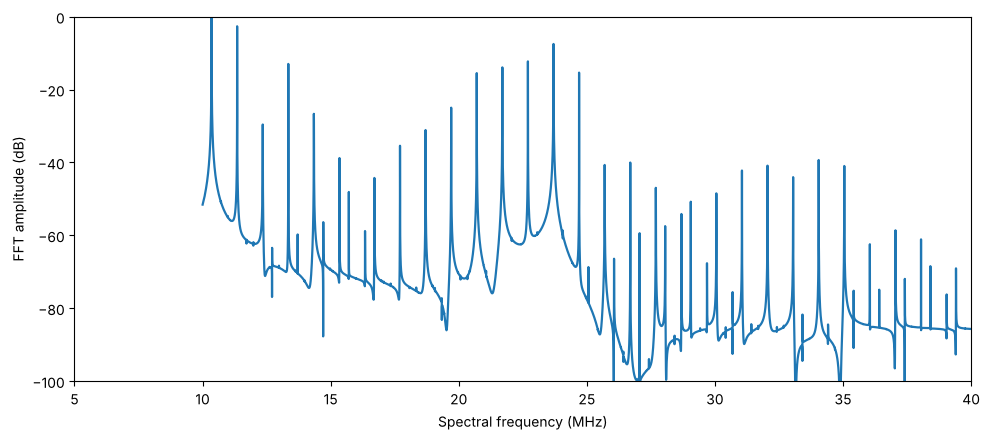

In [11]:
magDB = 20*np.log10(np.maximum(magNorm, 1e-10))

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(freqPlot, magDB, lw=1.6)
ax.set_xlim(5, 40); ax.set_ylim(-100, 0)
ax.set_xlabel("Spectral frequency (MHz)"); ax.set_ylabel("FFT amplitude (dB)")
plt.tight_layout(); plt.show()